## **Setup**


In [2]:
from pathlib import Path
import subprocess

repo_dir = Path("/content/VisionLab")

if (repo_dir / ".git").exists():
    subprocess.run(
        ["git", "-C", str(repo_dir), "pull", "--ff-only"],
        check=True,
    )
else:
    subprocess.run(
        ["git", "clone", "https://github.com/dohyunii/VisionLab", str(repo_dir)],
        check=True,
    )

%cd /content/VisionLab
%pip install -r requirements.txt


/content/VisionLab


In [3]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.is_available())

PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
GPU: False


In [4]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## **Experiment settings**

Defaults are shown in parentheses. Only `--arch` is required.

**Model and data**
- `--dataset`: `cifar10` or `cifar100` (**cifar10**)
- `--arch`: **required**
  - ResNet: `resnet18`, `resnet50`
  - PreActResNet: `preactresnet18`, `preactresnet50`
  - DenseNet: `densenet121`
  - FractalNet: `fractalnet20`, `fractalnet40`
  - VisionTransformer: `vitB4`, `vitB16`, `vitL32`
  - MLPMixer: `mlpmixerS4`, `mlpmixerB16`, `mlpmixerL32`
- `--method`: `supervised` (**supervised**)

**Classification head**
- `--head`: `linear` or `mlp` (**linear**)
- `--head_hidden_dim`: MLP hidden width (**backbone feature dimension**)
- `--head_activation`: `tanh`, `gelu`, or `relu` (**relu**)

**Training**
- `--batch_size`: images per batch (**128**)
- `--epochs`: training epochs (**100**)
- `--optimizer`: `sgd` or `adamw` (**sgd**)
- `--lr`: initial learning rate (**0.1**)
- `--momentum`: SGD momentum (**0.9**)
- `--weight_decay`: weight decay for the selected optimizer (**0.01**)

**Optimizer details**
- **SGD:** uses `--lr`, `--momentum`, and `--weight_decay`.
- **AdamW:** adaptive learning rates with decoupled weight decay; uses `--lr`
  and `--weight_decay`. Betas are `(0.9, 0.999)` and epsilon is `1e-8`.

**Execution**
- `--num_workers`: data-loading workers; `0` uses the main process (**2**)
- `--seed`: random seed (**42**)

**Storage**
- `--data_dir`: dataset directory (**<save_dir>/data** when omitted)
- `--save_dir`: experiment output directory (**./runs**)

This notebook explicitly separates persistent Drive storage:
- Dataset: `--data_dir /content/drive/MyDrive/VisionLab-data`
- Results: `--save_dir /content/drive/MyDrive/VisionLab-runs`

**Learning-rate schedule**

The learning rate is multiplied by `0.1` at the end of epochs
`int(epochs * 0.5)` and `int(epochs * 0.75)`.
For 100 epochs, these are epochs 50 and 75.

**Minimal command**

`python main.py --arch fractalnet20`


## **Run an experiment**


In [ ]:
!python main.py --arch vitB4 --head linear \
    --optimizer adamw --lr 0.0003 --weight_decay 0.01 \
    --data_dir /content/drive/MyDrive/VisionLab-data \
    --save_dir /content/drive/MyDrive/VisionLab-runs

Device: cuda
Shared dataset directory: /content/drive/MyDrive/VisionLab-data
Epoch 1/100: train_loss=1.9113 train_accuracy=28.26% lr=0.0003
Epoch 2/100: train_loss=1.6018 train_accuracy=40.35% lr=0.0003
Epoch 3/100: train_loss=1.4651 train_accuracy=46.35% lr=0.0003
Epoch 4/100: train_loss=1.4069 train_accuracy=48.39% lr=0.0003
Epoch 5/100: train_loss=1.3688 train_accuracy=49.84% lr=0.0003
Epoch 6/100: train_loss=1.3460 train_accuracy=50.63% lr=0.0003
Epoch 7/100: train_loss=1.3371 train_accuracy=51.31% lr=0.0003
Epoch 8/100: train_loss=1.3327 train_accuracy=51.48% lr=0.0003
Epoch 9/100: train_loss=1.3252 train_accuracy=51.43% lr=0.0003
Epoch 10/100: train_loss=1.3118 train_accuracy=52.44% lr=0.0003
Epoch 11/100: train_loss=1.2939 train_accuracy=52.98% lr=0.0003
Epoch 12/100: train_loss=1.2826 train_accuracy=53.37% lr=0.0003
Epoch 13/100: train_loss=1.2749 train_accuracy=53.55% lr=0.0003
Epoch 14/100: train_loss=1.2623 train_accuracy=54.14% lr=0.0003
Epoch 15/100: train_loss=1.2465 trai

## **Display the latest saved plot**


Experiment: cifar10_vitB4_supervised_20261124_124605_373807


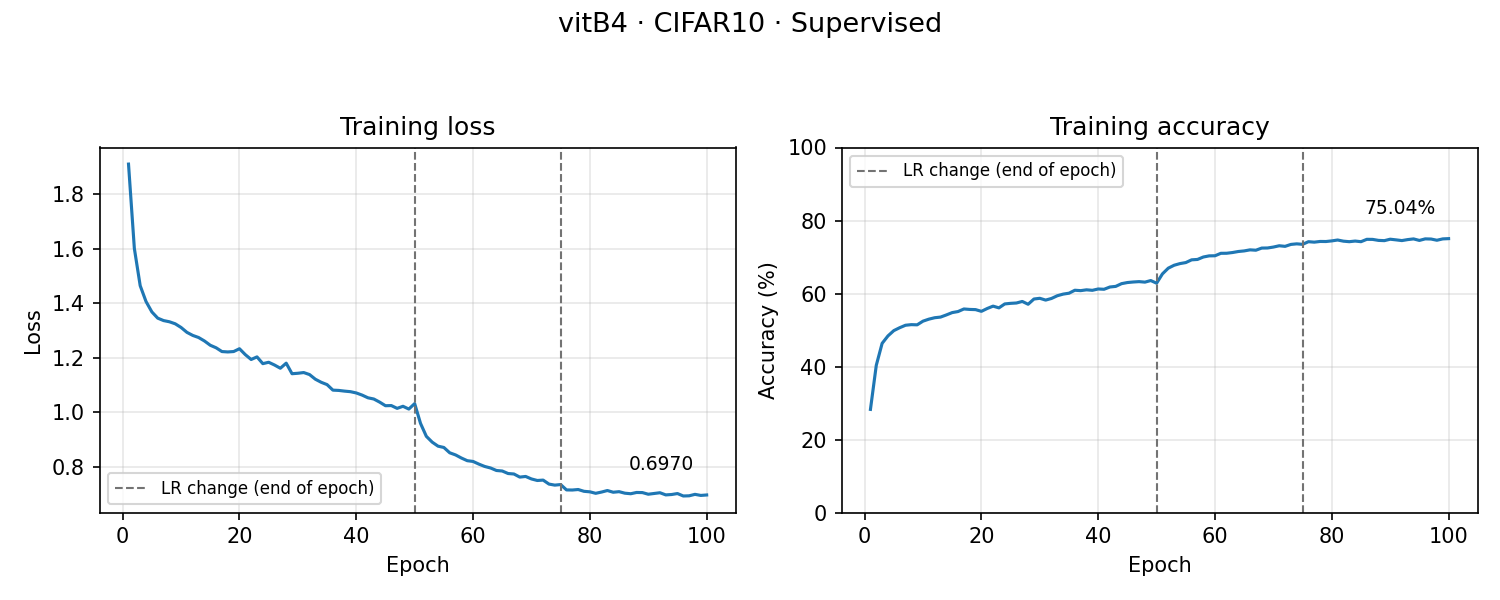

In [5]:
from pathlib import Path
from IPython.display import Image, display

output_dir = Path("/content/drive/MyDrive/VisionLab-runs")
plots = list(output_dir.glob("*/training_curves.png"))

if not plots:
    print("No training plots found. Check the output path and Drive mount.")
else:
    latest_plot = max(plots, key=lambda path: path.stat().st_mtime)
    print("Experiment:", latest_plot.parent.name)
    display(Image(filename=str(latest_plot)))